# RetailPulse: Exploratory Data Analysis

## Overview

Exploratory Data Analysis (EDA) is the process of examining and understanding a dataset through descriptive statistics, aggregations, and visualizations. It helps identify patterns, trends, relationships, and potential anomalies that may be useful for business decision-making.

In this notebook, the feature-engineered RetailPulse sales dataset will be analyzed to understand sales performance, order outcomes, product characteristics, and temporal patterns.

## Objectives

* Understand the overall structure and distribution of the dataset.
* Analyze the recorded sales value and revenue-related metrics.
* Examine order status and fulfilment patterns.
* Investigate product size and category distributions.
* Explore temporal patterns in order activity.
* Analyze geographical patterns where the available data supports them.
* Develop evidence-based business insights for the RetailPulse project.

## Approach

The analysis will proceed from general dataset exploration to focused business questions. Descriptive statistics and aggregations will be used to examine important measures, followed by visualizations to communicate the findings.

All conclusions will be based on the available dataset. Revenue-related metrics will follow the project's documented business rules and will not be interpreted as verified accounting revenue.

## Business Questions and Analysis Plan

The objective of this exploratory data analysis is to investigate the RetailPulse sales dataset and identify meaningful patterns related to monetary value, order outcomes, time, products, fulfilment, and geography.

The analysis will address the following business questions:

### Overall Sales Performance

* What is the total recorded monetary value across all sales records?
* What is the project-defined revenue from eligible orders?
* How many distinct orders are represented in the dataset?
* How does recorded quantity vary across the dataset?

### Order Status Analysis

* Which order statuses occur most frequently?
* What percentage of records belongs to each order status?
* How does recorded monetary value vary across order status groups?
* What proportion of records is cancelled or returned?

### Time-Based Analysis

* Which month has the highest number of records?
* Which month has the highest project-defined revenue?
* How does recorded monetary value change over the available period?
* Which weekdays have the highest order activity?

### Product and Size Analysis

* Which product sizes occur most frequently?
* How does recorded monetary value vary across size categories?
* Which product styles have the highest recorded monetary value?

### Fulfilment Analysis

* Which fulfilment methods occur most frequently?
* How are courier statuses distributed?
* How do order statuses vary by fulfilment method?

### Geographical Analysis

* Which states have the highest record counts?
* Which states have the most distinct orders?
* Which states have the highest project-defined revenue?

### Analysis Approach

Each question will be investigated using appropriate aggregations, descriptive statistics, and visualizations. Findings will be documented after reviewing the results.

Record counts, distinct order counts, recorded monetary amounts, and project-defined revenue will be treated as separate measures. Conclusions will be limited to patterns supported by the available data.


## 1. Load the Feature-Engineered Dataset

The processed dataset saved in the previous notebook will be loaded from the `data/processed/` directory.

The date column will be converted to a datetime data type to support temporal analysis. The dataset's dimensions, column names, and data types will then be inspected to establish the starting point for exploratory analysis.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

cleaned_csv = "../data/processed/cleaned_dataset.csv"

df = pd.read_csv(cleaned_csv)

df["date"] = pd.to_datetime(df["date"])

print("Feature-engineered dataset loaded successfully.")
print(f"Dataset shape: {df.shape}")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

Feature-engineered dataset loaded successfully.
Dataset shape: (128969, 25)
Number of rows: 128969
Number of columns: 25


### 2. Inspect the Dataset Structure

Before beginning the analysis, the dataset's column names, data types, and sample records will be examined.

This inspection helps confirm that the expected original and engineered features are available and identifies the appropriate columns for subsequent analysis.


In [4]:
print("Column names:")
print(df.columns.to_list())

print("\nData types:")
display(df.dtypes.to_frame(name="data_type"))

print("\nSample records:")
display(df.head(10))

Column names:
['order_id', 'date', 'status', 'fulfilment', 'sales_channel', 'ship_service_level', 'style', 'sku', 'category', 'size', 'asin', 'courier_status', 'qty', 'amount', 'ship_state', 'ship_country', 'b2b', 'fulfilled_by', 'year', 'month', 'month_name', 'day', 'order_status_group', 'size_category', 'revenue']

Data types:


,data_type
order_id,str
date,datetime64[us]
status,str
fulfilment,str
sales_channel,str
ship_service_level,str
style,str
sku,str
category,str
size,str



Sample records:


,order_id,date,status,fulfilment,sales_channel,ship_service_level,style,sku,category,size,...,ship_country,b2b,fulfilled_by,year,month,month_name,day,order_status_group,size_category,revenue
0,405-8078784-5731545,2022-04-30,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,S,...,IN,Customer,Easy Ship,2022,4,April,Saturday,Cancelled,Standard,0.0
1,171-9198151-1101146,2022-04-30,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,3XL,...,IN,Customer,Easy Ship,2022,4,April,Saturday,Delivered,Extended,406.0
2,404-0687676-7273146,2022-04-30,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,XL,...,IN,Business,Unknown,2022,4,April,Saturday,In Progress,Standard,329.0
3,403-9615377-8133951,2022-04-30,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,L,...,IN,Customer,Easy Ship,2022,4,April,Saturday,Cancelled,Standard,0.0
4,407-1069790-7240320,2022-04-30,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,3XL,...,IN,Customer,Unknown,2022,4,April,Saturday,In Progress,Extended,574.0
5,404-1490984-4578765,2022-04-30,Shipped,Amazon,Amazon.in,Expedited,SET264,SET264-KR-NP-XL,Set,XL,...,IN,Customer,Unknown,2022,4,April,Saturday,In Progress,Standard,824.0
6,408-5748499-6859555,2022-04-30,Shipped,Amazon,Amazon.in,Expedited,J0095,J0095-SET-L,Set,L,...,IN,Customer,Unknown,2022,4,April,Saturday,In Progress,Standard,653.0
7,406-7807733-3785945,2022-04-30,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3405,JNE3405-KR-S,kurta,S,...,IN,Customer,Easy Ship,2022,4,April,Saturday,Delivered,Standard,399.0
8,407-5443024-5233168,2022-04-30,Cancelled,Amazon,Amazon.in,Expedited,SET200,SET200-KR-NP-A-XXXL,Set,3XL,...,IN,Customer,Unknown,2022,4,April,Saturday,Cancelled,Extended,0.0
9,402-4393761-0311520,2022-04-30,Shipped,Amazon,Amazon.in,Expedited,JNE3461,JNE3461-KR-XXL,kurta,XXL,...,IN,Customer,Unknown,2022,4,April,Saturday,In Progress,Standard,363.0


### 3. Verify Data Quality

Before conducting exploratory analysis, the dataset will be checked for missing values, duplicate records, and data type consistency.

Although these checks were performed in the previous notebooks, repeating them here helps confirm that the processed dataset is ready for analysis.


In [10]:
print("Dataset dimensions:")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nExact duplicate records:")
print(df.duplicated().sum())

print("\nMissing values by column:")
df.isnull().sum().to_frame(name="missing_values")

Dataset dimensions:
Rows: 128,969
Columns: 25

Total missing values:
0

Exact duplicate records:
0

Missing values by column:


,missing_values
order_id,0
date,0
status,0
fulfilment,0
sales_channel,0
ship_service_level,0
style,0
sku,0
category,0
size,0


### 4. Explore Numerical Distributions

Descriptive statistics provide an initial overview of the numerical variables in the dataset. Measures such as the mean, median, minimum, maximum, and quartiles help us understand typical values, variation, and potential anomalies.

This analysis will cover the numerical columns, including quantity, amount, and the engineered revenue measure.


In [15]:
numeric_columns = df.select_dtypes(include="number").columns

print("Numerical columns:")
print(numeric_columns.to_list())

print("\nDescriptive statistics:")
df[numeric_columns].describe().T

Numerical columns:
['qty', 'amount', 'year', 'month', 'revenue']

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
qty,128969.0,0.904450,0.313330,0.0,1.0,1.0,1.0,15.0
amount,128969.0,609.371580,313.335444,0.0,413.0,583.0,771.0,5584.0
year,128969.0,2022.000000,0.000000,2022.0,2022.0,2022.0,2022.0,2022.0
month,128969.0,4.909195,0.818408,3.0,4.0,5.0,6.0,6.0
revenue,128969.0,544.960936,352.025761,0.0,363.0,537.0,759.0,5584.0


### 5. Analyze Overall Sales Performance

This section examines the overall sales-related metrics in the RetailPulse dataset to establish a baseline for further analysis.

The analysis will calculate the total recorded amount, project-defined revenue, number of distinct orders, total recorded quantity, and average recorded amount per record.

These metrics provide an initial overview of monetary values and order activity. The distinction between individual records and distinct orders will be maintained because an order may contain multiple records.


In [19]:
total_records = len(df)
total_recorded_amount = df["amount"].sum()
total_revenue = df["revenue"].sum()
distinct_orders = df["order_id"].nunique()
total_quantity = df["qty"].sum()
average_record_amount = df["amount"].mean()

overall_metrics = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Total Recorded Amount",
        "Project-Defined Revenue",
        "Distinct Orders",
        "Total Recorded Quantity",
        "Average Amount per Record"
    ],
    "Value": [
        total_records,
        total_recorded_amount,
        total_revenue,
        distinct_orders,
        total_quantity,
        average_record_amount
    ]
})

overall_metrics

,Metric,Value
0,Total Records,1.289690e+05
1,Total Recorded Amount,7.859004e+07
2,Project-Defined Revenue,7.028307e+07
3,Distinct Orders,1.203780e+05
4,Total Recorded Quantity,1.166460e+05
5,Average Amount per Record,6.093716e+02


### 6. Analyze Order Status Distribution

Understanding order status distribution helps reveal the composition of the RetailPulse dataset and the relative frequency of different order outcomes.

This section examines the record counts and percentages for each original order status. It will help identify the most common statuses and highlight less frequent outcomes.

Record counts will be used rather than distinct order counts in this section. Since an order ID may appear in multiple records, the results represent the distribution of dataset records rather than the distribution of unique orders.


In [21]:
status_counts = df["status"].value_counts()

status_percentages = (
    df["status"].value_counts(normalize=True).mul(100)
)

status_summary = pd.DataFrame({
    "record_count": status_counts,
    "percentage": status_percentages
})

status_summary.round(2)

,record_count,percentage
status,,
Shipped,77801,60.33
Shipped - Delivered to Buyer,28769,22.31
Cancelled,18329,14.21
Shipped - Returned to Seller,1953,1.51
Shipped - Picked Up,973,0.75
Pending,658,0.51
Pending - Waiting for Pick Up,281,0.22
Shipped - Returning to Seller,145,0.11
Shipped - Out for Delivery,35,0.03


### 6.1 Visualize Order Status Distribution

A horizontal bar chart provides a clear comparison of the number of records associated with each order status. Sorting the statuses by record count makes the most frequent statuses easy to identify while keeping less common statuses visible.

The chart represents record counts rather than distinct orders.


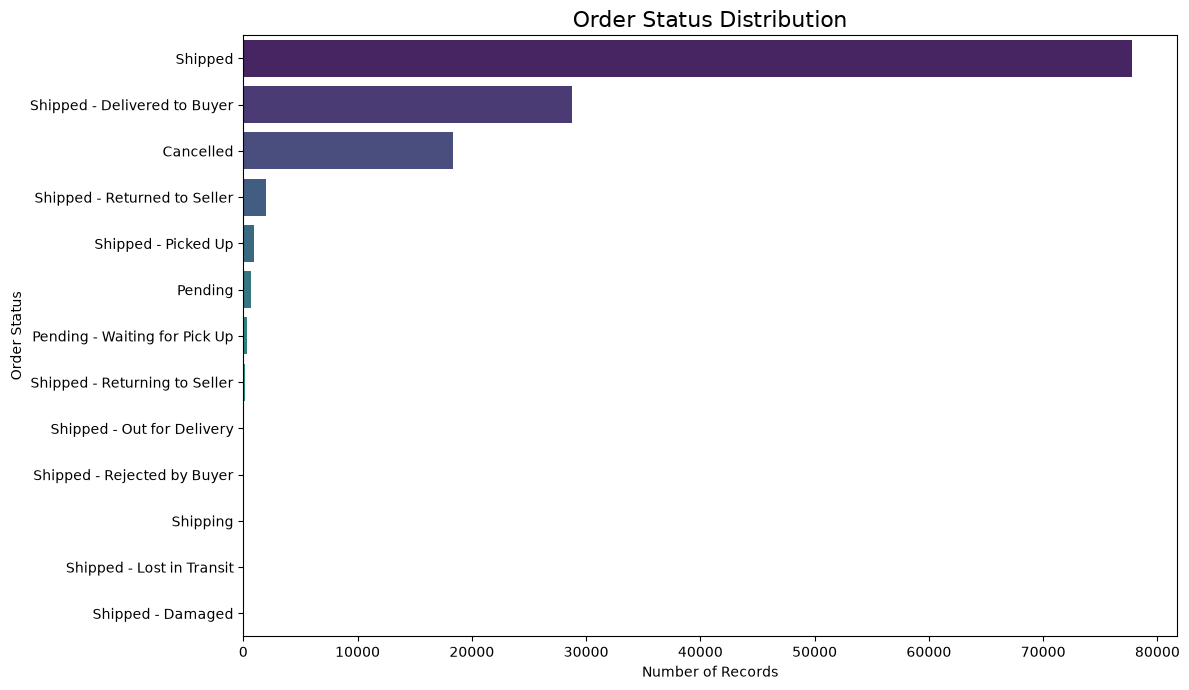

In [22]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=status_summary.reset_index(),
    x="record_count",
    y="status",
    hue="status",
    palette="viridis",
    legend=False
)

plt.title("Order Status Distribution", fontsize=16)
plt.xlabel("Number of Records")
plt.ylabel("Order Status")
plt.tight_layout()
plt.show()

### 7. Analyze Order Status Groups

The original dataset contains multiple order statuses that represent similar outcomes. Grouping these statuses into broader categories makes it easier to understand the overall composition of order activity.

This section examines the record count and percentage for each `order_status_group`. It will help compare delivered, cancelled, returned, rejected, in-progress, and other records.

The analysis uses record counts rather than distinct order counts. The group definitions follow the mapping established during feature engineering in Notebook 4.


In [25]:
group_counts = df["order_status_group"].value_counts()

group_percentages = (
    df["order_status_group"].value_counts(normalize=True).mul(100)
)

group_summary = pd.DataFrame({
    "record_count": group_counts,
    "percentage": group_percentages
})

group_summary.round(2)

,record_count,percentage
order_status_group,,
In Progress,79756,61.84
Delivered,28769,22.31
Cancelled,18329,14.21
Returned,2098,1.63
Rejected,11,0.01
Other,6,0.00


### 7.1 Visualize Order Status Groups

A horizontal bar chart will compare the record counts across the six consolidated order status groups.

This visualization makes it easier to identify the dominant categories and compare the frequency of delivered, cancelled, returned, rejected, and other records. The chart uses the same group definitions established during feature engineering.


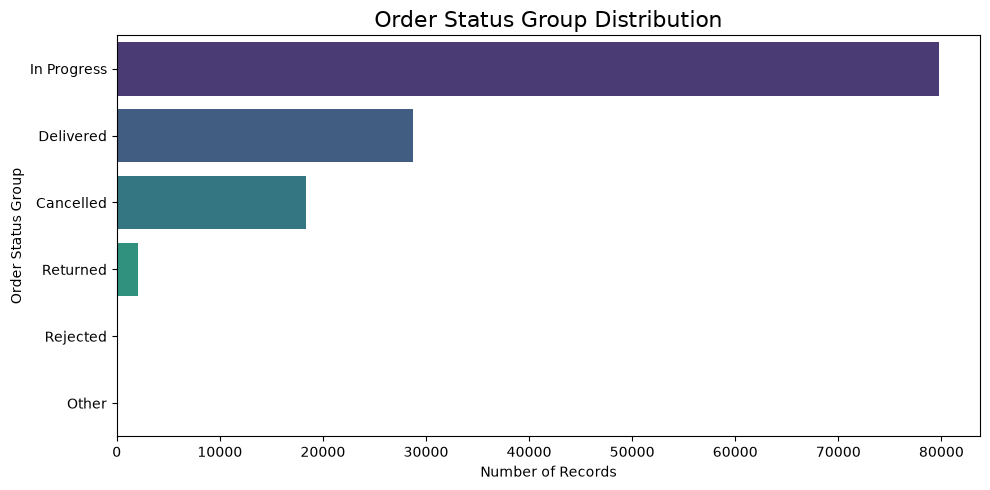

In [26]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=group_summary.reset_index(),
    x="record_count",
    y="order_status_group",
    hue="order_status_group",
    palette="viridis",
    legend=False
)

plt.title("Order Status Group Distribution", fontsize=16)
plt.xlabel("Number of Records")
plt.ylabel("Order Status Group")
plt.tight_layout()
plt.show()

### 8. Analyze Monthly Sales Performance

Analyzing monthly performance helps reveal changes in sales activity throughout the year and identify months with higher recorded amounts and project-defined revenue.

This section groups the records by month and calculates the number of records, distinct orders, total recorded amount, and project-defined revenue.

The analysis uses the `month` and `month_name` features created during feature engineering. Revenue follows the project-defined business rule established in Notebook 4 and should not be interpreted as verified accounting revenue.


In [ ]:
monthly_summary = (
    df.groupby(["month", "month_name"])
    .agg(
        record_count=("order_id", "size"),
        distinct_orders=("order_id", "nunique"),
        total_recorded_amount=("amount", "sum"),
        project_defined_revenue=("revenue", "sum")
    )
    .reset_index().sort_values("month")
)

monthly_summary.round(2)

,month,month_name,record_count,distinct_orders,total_recorded_amount,project_defined_revenue
0,3,March,171,158,101683.85,94183.0
1,4,April,49065,45858,28838708.32,25669247.0
2,5,May,42037,39221,26225004.75,23469712.0
3,6,June,37696,35141,23424646.38,21049925.0


### 8.1 Visualize Monthly Sales Performance

A line chart will help illustrate how total recorded amount and project-defined revenue change across the months represented in the dataset.

Comparing these two measures will show whether their monthly trends follow a similar pattern. The chart will use the chronological month order rather than alphabetical sorting.

Only the months available in the dataset will be displayed.


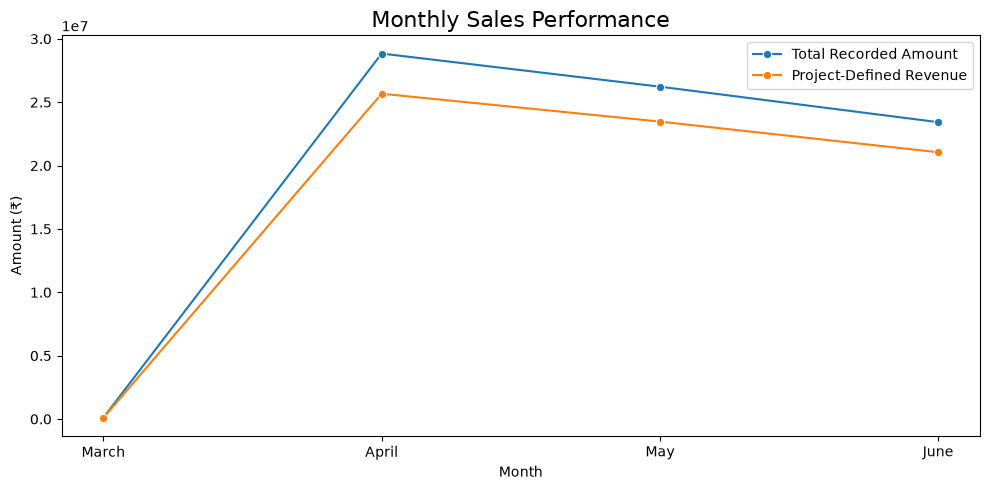

In [32]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=monthly_summary,
    x="month_name",
    y="total_recorded_amount",
    marker="o",
    label="Total Recorded Amount"
)

sns.lineplot(
    data=monthly_summary,
    x="month_name",
    y="project_defined_revenue",
    marker="o",
    label="Project-Defined Revenue"
)

plt.title("Monthly Sales Performance", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Amount (₹)")
plt.xticks(
    ticks=range(len(monthly_summary)),
    labels=monthly_summary["month_name"]
)
plt.legend()
plt.tight_layout()
plt.show()

### 8.2 Analyze Monthly Order Activity

Monthly order activity helps compare the volume of records and distinct orders across the months represented in the dataset.

This section examines the number of records and unique order IDs for each month. Comparing these measures helps distinguish dataset record volume from the number of distinct orders, since an order may contain multiple records.


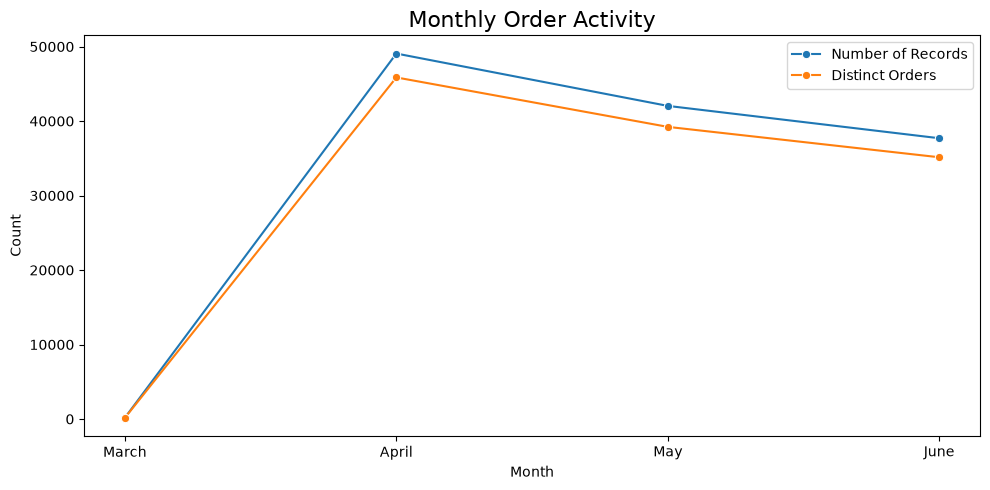

In [37]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=monthly_summary,
    x="month_name",
    y="record_count",
    marker="o",
    label="Number of Records"
)

sns.lineplot(
    data=monthly_summary,
    x="month_name",
    y="distinct_orders",
    marker="o",
    label="Distinct Orders"
)

plt.title("Monthly Order Activity", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Count")
plt.legend()
plt.tight_layout()
plt.show()

### 9. Analyze Sales Performance by Weekday

Analyzing sales performance by weekday helps compare recorded monetary values and project-defined revenue across different days of the week.

This section groups records by weekday and calculates the number of records, distinct orders, total recorded amount, and project-defined revenue.

The weekday order will follow the calendar, from Monday through Sunday, rather than alphabetical order.


In [39]:
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_summary = (
    df.groupby("day")
    .agg(
        record_count=("order_id", "size"),
        distinct_orders=("order_id", "nunique"),
        total_recorded_amount=("amount", "sum"),
        project_defined_revenue=("revenue", "sum")
    )
    .reindex(weekday_order).reset_index().rename(columns={"index": "day"})
)

weekday_summary.round(2)

,day,record_count,distinct_orders,total_recorded_amount,project_defined_revenue
0,Monday,18568,17367,11318441.14,10097377.0
1,Tuesday,18879,17587,11490154.07,10263515.0
2,Wednesday,18593,17370,11248660.35,10086317.0
3,Thursday,17069,16005,10358594.27,9304008.0
4,Friday,17718,16580,10805394.60,9652001.0
5,Saturday,18523,17263,11339357.57,10110946.0
6,Sunday,19619,18206,12029441.30,10768903.0


### 9.1 Visualize Sales Performance by Weekday

A line chart will compare total recorded amount and project-defined revenue across the seven weekdays.

The visualization will help identify days with relatively higher or lower monetary values and show whether the two measures follow similar patterns. Weekdays will be displayed in calendar order, from Monday through Sunday.


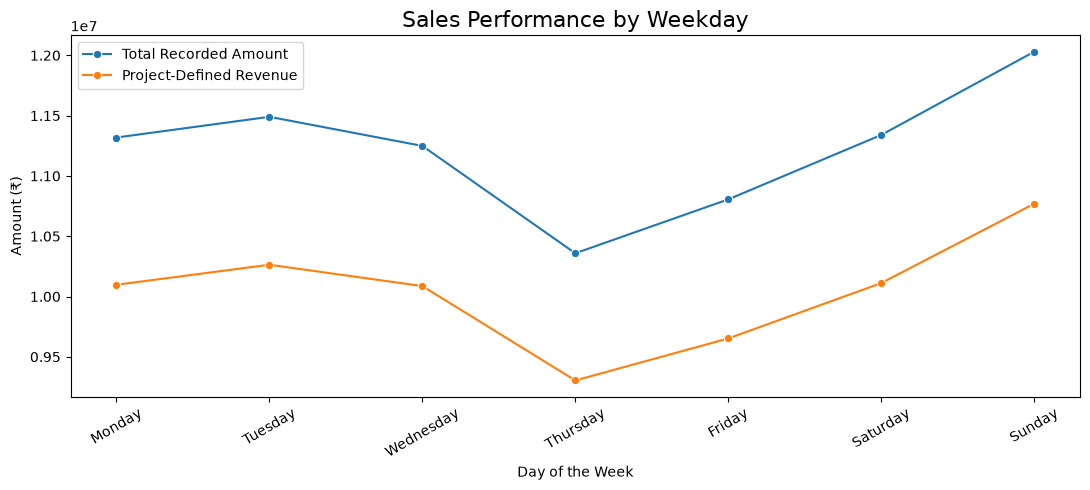

In [44]:
plt.figure(figsize=(11, 5))

sns.lineplot(
    data=weekday_summary,
    x="day",
    y="total_recorded_amount",
    marker="o",
    label="Total Recorded Amount"
)

sns.lineplot(
    data=weekday_summary,
    x="day",
    y="project_defined_revenue",
    marker="o",
    label="Project-Defined Revenue"
)

plt.title("Sales Performance by Weekday", fontsize=16)
plt.xlabel("Day of the Week")
plt.ylabel("Amount (₹)")
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()
plt.show()

### 10. Analyze Product Size Distribution

Product size analysis helps identify the size categories that appear most frequently in the dataset.

This section examines the number of records and their percentage across the available size categories. It will help determine whether standard sizes, extended sizes, or free-size products account for the largest share of recorded activity.

The analysis uses the `size_category` feature created during feature engineering in Notebook 4.


In [45]:
size_counts = df["size_category"].value_counts()

size_percentages = (
    df["size_category"].value_counts(normalize=True).mul(100)
)

size_summary = pd.DataFrame({
    "record_count": size_counts,
    "percentage": size_percentages
})

size_summary.round(2)

,record_count,percentage
size_category,,
Standard,112061,86.89
Extended,16530,12.82
Free Size,378,0.29


### 10.1 Visualize Product Size Distribution

A bar chart provides a clear comparison of record counts across the three product size categories.

This visualization highlights the dominance of standard sizes and shows the relative contribution of extended and free-size products to the dataset.


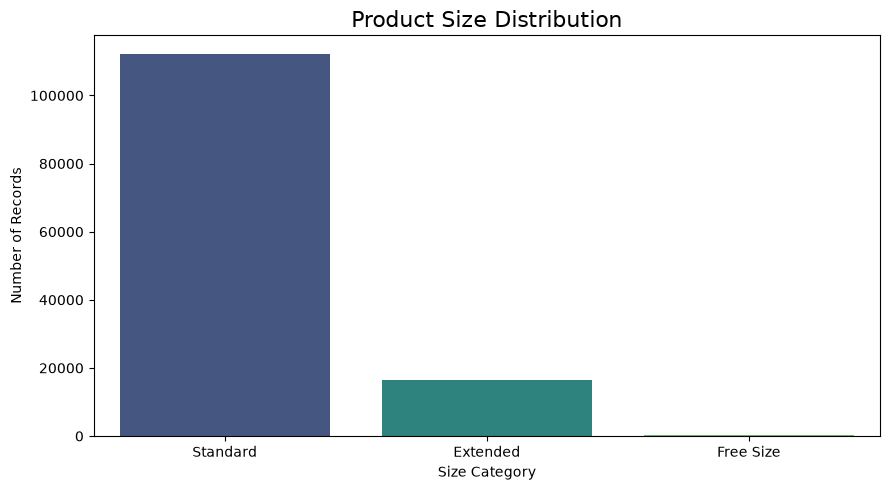

In [51]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=size_summary.reset_index(),
    x="size_category",
    y="record_count",
    hue="size_category",
    palette="viridis",
    legend=False
)

plt.title("Product Size Distribution", fontsize=16)
plt.xlabel("Size Category")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

### 11. Analyze Sales Performance by Product Size

This section compares monetary performance across the product size categories: Standard, Extended, and Free Size.

For each category, the analysis calculates the number of records, total recorded quantity, total recorded amount, and project-defined revenue.

These measures will help compare the monetary contribution and recorded quantity of each category. The results represent dataset records and follow the project-defined revenue rule established during feature engineering.


In [52]:
size_sales_summary = (
    df.groupby("size_category")
    .agg(
        record_count=("order_id", "size"),
        total_quantity=("qty", "sum"),
        total_recorded_amount=("amount", "sum"),
        project_defined_revenue=("revenue", "sum")
    )
    .sort_values("total_recorded_amount", ascending=False)
)

size_sales_summary.round(2)

,record_count,total_quantity,total_recorded_amount,project_defined_revenue
size_category,,,,
Standard,112061,101158,67892378.25,60567917.0
Extended,16530,15122,10492472.28,9529365.0
Free Size,378,366,205192.77,185785.0


### 11.1 Visualize Sales Performance by Product Size

A grouped bar chart will compare total recorded amount and project-defined revenue across Standard, Extended, and Free Size categories.

Displaying both measures side by side will help compare their relative monetary contributions and determine whether the categories follow a similar ranking.


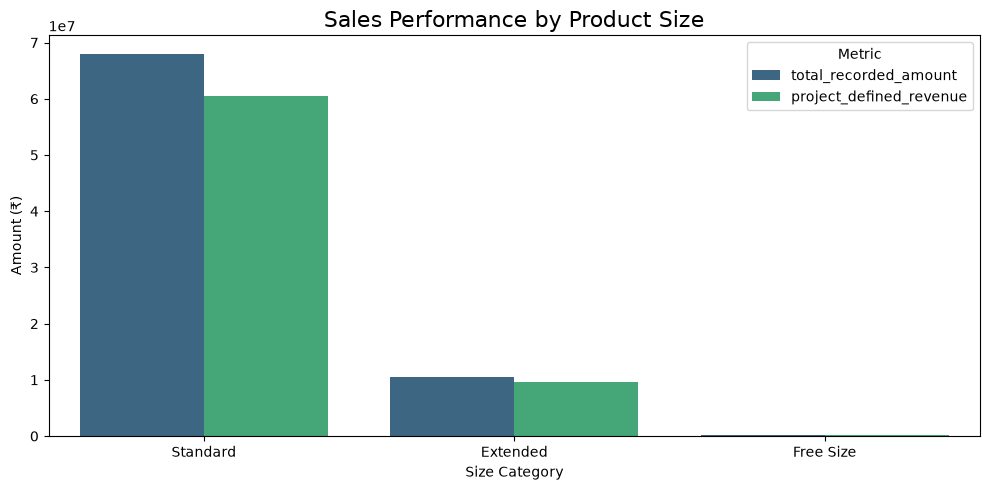

In [53]:
size_sales_plot = (
    size_sales_summary
    .reset_index()
    .melt(
        id_vars="size_category",
        value_vars=[
            "total_recorded_amount",
            "project_defined_revenue"
        ],
        var_name="metric",
        value_name="amount"
    )
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=size_sales_plot,
    x="size_category",
    y="amount",
    hue="metric",
    palette="viridis"
)

plt.title("Sales Performance by Product Size", fontsize=16)
plt.xlabel("Size Category")
plt.ylabel("Amount (₹)")
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

### 12. Analyze Top Product Styles

Product style analysis helps identify the styles associated with the highest total recorded amounts.

This section groups records by product style and calculates the number of records, total recorded quantity, total recorded amount, and project-defined revenue.

The results will be sorted by total recorded amount to identify the highest-ranking styles. This analysis measures monetary contribution within the dataset rather than profitability, since product costs and profit margins are not available.


In [55]:
style_summary = (
    df.groupby("style")
    .agg(
        record_count=("order_id", "size"),
        total_quantity=("qty", "sum"),
        total_recorded_amount=("amount", "sum"),
        project_defined_revenue=("revenue", "sum")
    )
    .sort_values("total_recorded_amount", ascending=False)
)

style_summary.head(10).round(2)

,record_count,total_quantity,total_recorded_amount,project_defined_revenue
style,,,,
JNE3797,4224,3692,2933482.00,2545827.0
J0230,1867,1709,1943785.48,1777465.0
SET268,1860,1731,1303923.56,1190008.0
J0341,1630,1471,1275322.87,1135086.0
J0003,1627,1390,981973.75,842294.0
JNE3405,2263,2067,846822.36,761545.0
J0008,831,762,819169.96,747421.0
SET345,1250,1134,723402.79,659331.0
SET324,1284,1152,720096.82,632452.0


### 12.1 Visualize the Top 10 Product Styles

A horizontal bar chart will compare the top 10 product styles by total recorded amount.

Sorting the styles in descending order makes it easier to identify the highest-ranking styles and compare their monetary contributions. The visualization focuses on total recorded amount rather than profitability.


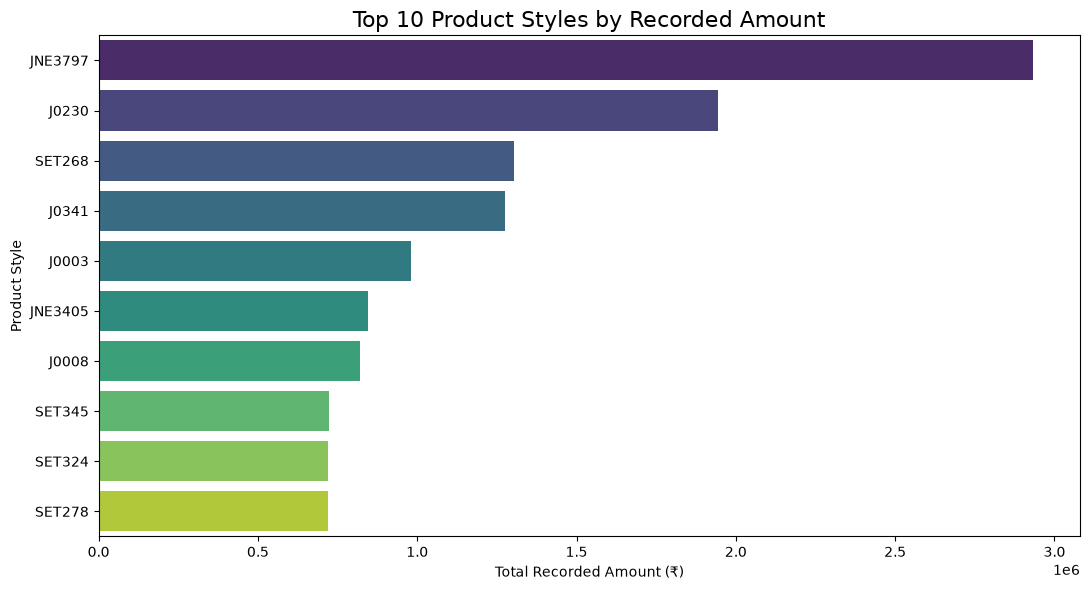

In [56]:
top_10_styles = style_summary.head(10).reset_index()

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_10_styles,
    x="total_recorded_amount",
    y="style",
    hue="style",
    palette="viridis",
    legend=False
)

plt.title("Top 10 Product Styles by Recorded Amount", fontsize=16)
plt.xlabel("Total Recorded Amount (₹)")
plt.ylabel("Product Style")
plt.tight_layout()
plt.show()

### 13. Analyze Fulfilment Methods

Fulfilment analysis helps identify the methods used to process and fulfil customer orders.

This section examines the number of records and their percentage across the available fulfilment methods. It will help identify the most frequently recorded fulfilment method and compare its representation with other methods.

The analysis uses the `fulfilled_by` column from the cleaned dataset.


In [ ]:
fulfilment_counts = df["fulfilled_by"].value_counts()

fulfilment_percentages = (
    df["fulfilled_by"]
    .value_counts(normalize=True)
    .mul(100)
)

fulfilment_summary = pd.DataFrame({
    "record_count": fulfilment_counts,
    "percentage": fulfilment_percentages
})

fulfilment_summary.round(2)

,record_count,percentage
fulfilled_by,,
Unknown,89692,69.55
Easy Ship,39277,30.45


### 13.1 Visualize Fulfilment Methods

A bar chart compares the number of records associated with each fulfilment category.

The visualization highlights the proportion of records with an identified fulfilment method versus those classified as Unknown during data cleaning. Unknown represents missing information rather than a confirmed fulfilment method.


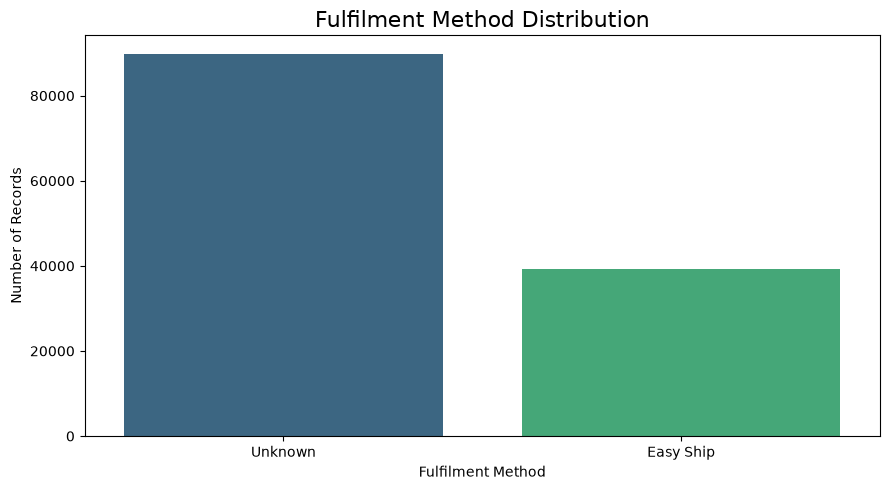

In [60]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=fulfilment_summary.reset_index(),
    x="fulfilled_by",
    y="record_count",
    hue="fulfilled_by",
    palette="viridis",
    legend=False
)

plt.title("Fulfilment Method Distribution", fontsize=16)
plt.xlabel("Fulfilment Method")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

### 14. Analyze Courier Status Distribution

Courier status analysis helps examine the shipment-related status information recorded in the dataset.

This section calculates the number of records and their percentage for each courier status. It will help identify the most frequently recorded courier statuses and compare their representation across the dataset.

The analysis uses the `courier_status` column from the cleaned dataset. Missing values were filled with `Unshipped` during data cleaning, so this category should be interpreted according to that preprocessing decision.


In [ ]:
courier_counts = df["courier_status"].value_counts()

courier_percentages = (
    df["courier_status"].value_counts(normalize=True).mul(100)
)

courier_summary = pd.DataFrame({
    "record_count": courier_counts,
    "percentage": courier_percentages
})

courier_summary.round(2)

,record_count,percentage
courier_status,,
Shipped,109484,84.89
Unshipped,13553,10.51
Cancelled,5932,4.60


### 14.1 Visualize Courier Status Distribution

A horizontal bar chart compares the number of records associated with each courier status.

This visualization highlights the dominance of the Shipped category and shows the relative proportions of Unshipped and Cancelled records. The Unshipped category should be interpreted with the data-cleaning decision that missing courier statuses were assigned this value.


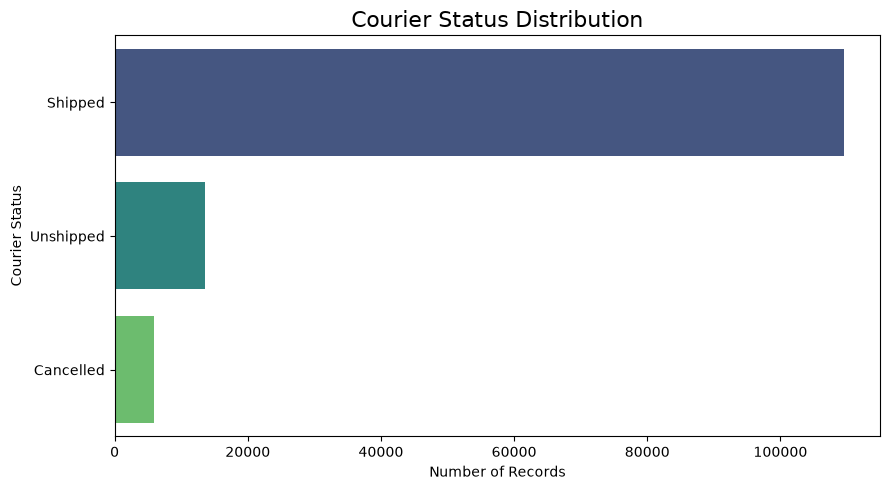

In [63]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=courier_summary.reset_index(),
    x="record_count",
    y="courier_status",
    hue="courier_status",
    palette="viridis",
    legend=False
)

plt.title("Courier Status Distribution", fontsize=16)
plt.xlabel("Number of Records")
plt.ylabel("Courier Status")
plt.tight_layout()
plt.show()

### 15. Analyze Order Status by Fulfilment Method

Examining order status alongside fulfilment method helps explore how the original order statuses are distributed across fulfilment categories.

This section uses a cross-tabulation to calculate the number of records for each combination of `status` and `fulfilled_by`. It will help identify differences in the recorded status distribution between Easy Ship and records classified as Unknown.

Unknown represents missing fulfilment information assigned during data cleaning, rather than a confirmed fulfilment method. The results describe record counts, not distinct orders.


In [65]:
status_fulfilment_summary = pd.crosstab(
    df["status"],
    df["fulfilled_by"]
)

status_fulfilment_summary

fulfilled_by,Easy Ship,Unknown
status,,
Cancelled,6861,11468
Pending,243,415
Pending - Waiting for Pick Up,281,0
Shipped,0,77801
Shipped - Damaged,1,0
Shipped - Delivered to Buyer,28769,0
Shipped - Lost in Transit,5,0
Shipped - Out for Delivery,35,0
Shipped - Picked Up,973,0


### 15.1 Visualize Order Status by Fulfilment Method

A stacked bar chart will compare the distribution of original order statuses across the fulfilment categories.

Each bar represents a fulfilment category, with segments showing the record counts for individual order statuses. This visualization will help identify which statuses contribute most to each category.

Unknown represents missing fulfilment information assigned during data cleaning, rather than a confirmed fulfilment method.


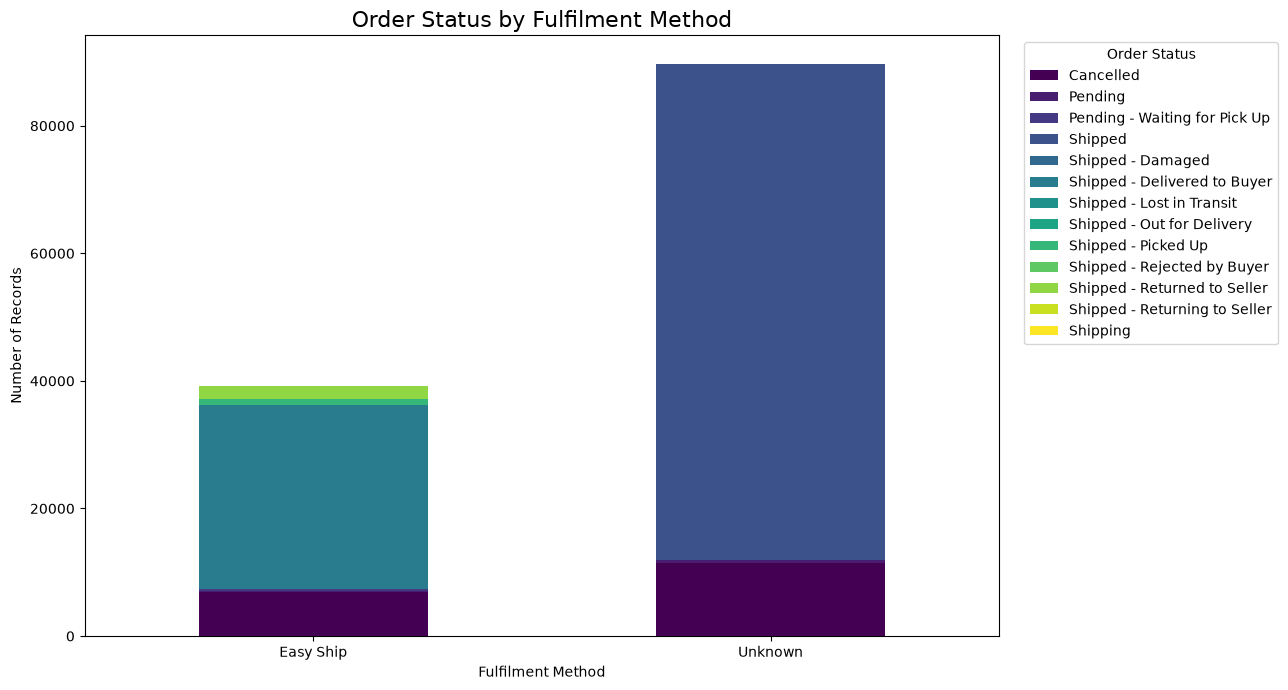

In [66]:
status_fulfilment_summary.T.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 7),
    colormap="viridis"
)

plt.title("Order Status by Fulfilment Method", fontsize=16)
plt.xlabel("Fulfilment Method")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.legend(
    title="Order Status",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

### 16. Analyze Revenue by Fulfilment Method

This section compares monetary performance across the fulfilment categories recorded in the dataset.

For each category, the analysis calculates the number of records, distinct orders, total recorded amount, and project-defined revenue.

The results will help compare the monetary values associated with Easy Ship and records classified as Unknown. Since Unknown represents missing fulfilment information, it should not be interpreted as an actual fulfilment method.

Project-defined revenue follows the business rule established during feature engineering in Notebook 4.


In [68]:
fulfilment_sales_summary = (
    df.groupby("fulfilled_by")
    .agg(
        record_count=("order_id", "size"),
        distinct_orders=("order_id", "nunique"),
        total_recorded_amount=("amount", "sum"),
        project_defined_revenue=("revenue", "sum")
    )
    .sort_values("total_recorded_amount", ascending=False)
)

fulfilment_sales_summary.round(2)

,record_count,distinct_orders,total_recorded_amount,project_defined_revenue
fulfilled_by,,,,
Unknown,89692,84002,54319516.0,50590404.0
Easy Ship,39277,36376,24270527.3,19692663.0


### 16.1 Visualize Monetary Performance by Fulfilment Category

A grouped bar chart compares total recorded amount and project-defined revenue across the fulfilment categories.

This visualization helps compare the monetary values associated with Easy Ship and records classified as Unknown. The Unknown category represents missing fulfilment information rather than a confirmed fulfilment method.


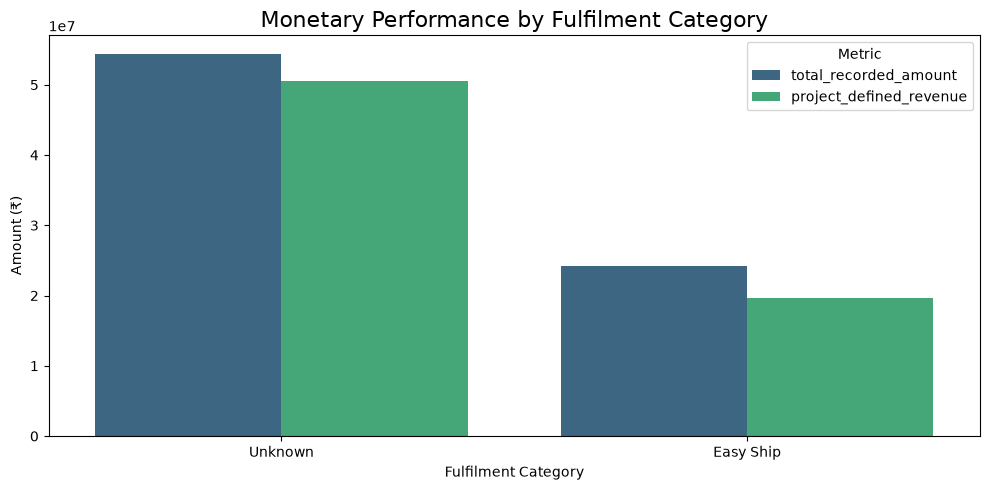

In [69]:
fulfilment_sales_plot = (
    fulfilment_sales_summary
    .reset_index()
    .melt(
        id_vars="fulfilled_by",
        value_vars=[
            "total_recorded_amount",
            "project_defined_revenue"
        ],
        var_name="metric",
        value_name="amount"
    )
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=fulfilment_sales_plot,
    x="fulfilled_by",
    y="amount",
    hue="metric",
    palette="viridis"
)

plt.title("Monetary Performance by Fulfilment Category", fontsize=16)
plt.xlabel("Fulfilment Category")
plt.ylabel("Amount (₹)")
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

### 17. Analyze Revenue by Order Status Group

This section compares total recorded amount and project-defined revenue across the consolidated order status groups.

The analysis will calculate the record count, total recorded amount, and project-defined revenue for each group. It will help identify how monetary values are distributed across delivered, cancelled, returned, rejected, in-progress, and other records.

Project-defined revenue follows the business rule established during feature engineering in Notebook 4. It should not be interpreted as verified accounting revenue.


In [70]:
status_group_sales_summary = (
    df.groupby("order_status_group")
    .agg(
        record_count=("order_id", "size"),
        total_recorded_amount=("amount", "sum"),
        project_defined_revenue=("revenue", "sum")
    )
    .sort_values("project_defined_revenue", ascending=False)
)

status_group_sales_summary.round(2)

,record_count,total_recorded_amount,project_defined_revenue
order_status_group,,,
In Progress,79756,51632252.0,51632252.0
Delivered,28769,18650815.0,18650815.0
Cancelled,18329,6919284.3,0.0
Other,6,3133.0,0.0
Rejected,11,7295.0,0.0
Returned,2098,1377264.0,0.0


### 17.1 Visualize Monetary Values by Order Status Group

A grouped bar chart compares total recorded amount and project-defined revenue across the consolidated order status groups.

This visualization highlights the difference between recorded monetary values and the project-defined revenue measure. Cancelled, returned, rejected, and other records may contain recorded amounts even though their project-defined revenue is zero under the business rule established during feature engineering.


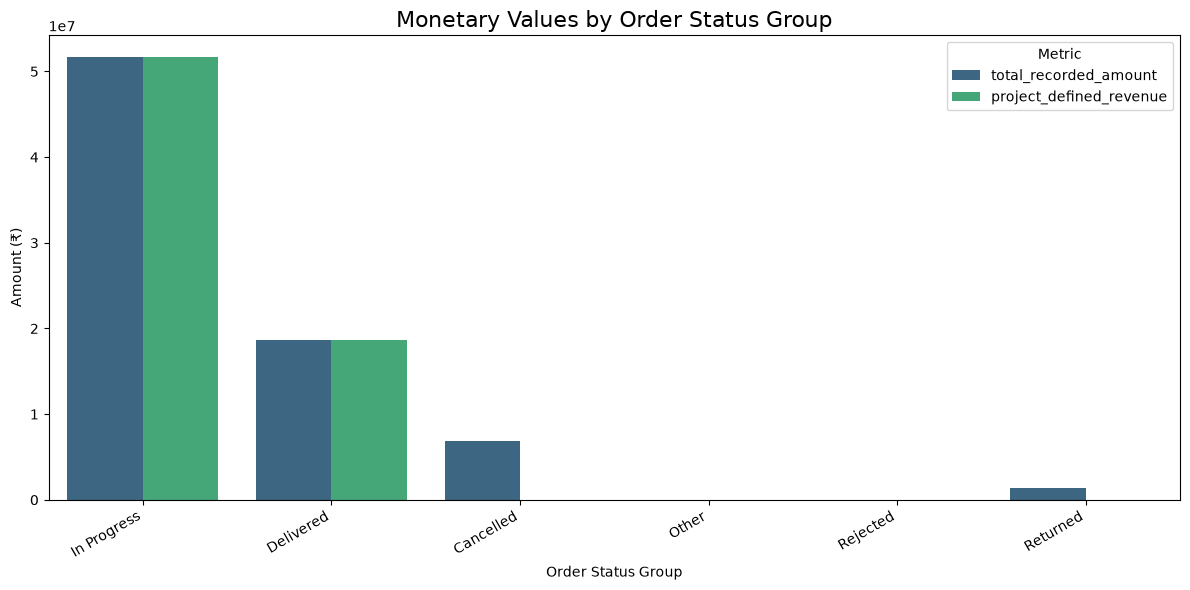

In [71]:
status_group_sales_plot = (
    status_group_sales_summary
    .reset_index()
    .melt(
        id_vars="order_status_group",
        value_vars=[
            "total_recorded_amount",
            "project_defined_revenue"
        ],
        var_name="metric",
        value_name="amount"
    )
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=status_group_sales_plot,
    x="order_status_group",
    y="amount",
    hue="metric",
    palette="viridis"
)

plt.title("Monetary Values by Order Status Group", fontsize=16)
plt.xlabel("Order Status Group")
plt.ylabel("Amount (₹)")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

### 18. Analyze Geographical Sales Performance

Geographical analysis helps compare order activity and monetary values across shipping states.

This section groups records by `ship_state` and calculates the number of records, distinct orders, total recorded amount, and project-defined revenue. The results will help identify states with higher recorded activity and monetary contributions.

Records with a shipping state classified as Unknown will remain in the analysis so that the summary accounts for the full dataset. Project-defined revenue follows the business rule established during feature engineering in Notebook 4.


In [73]:
state_sales_summary = (
    df.groupby("ship_state")
    .agg(
        record_count=("order_id", "size"),
        distinct_orders=("order_id", "nunique"),
        total_recorded_amount=("amount", "sum"),
        project_defined_revenue=("revenue", "sum")
    )
    .sort_values("project_defined_revenue", ascending=False)
)

state_sales_summary.head(15).round(2)

,record_count,distinct_orders,total_recorded_amount,project_defined_revenue
ship_state,,,,
MAHARASHTRA,22259,20780,13334595.14,12053998.0
KARNATAKA,17325,16182,10481114.37,9522813.0
TELANGANA,11330,10405,6916615.65,6184512.0
UTTAR PRADESH,10637,10062,6816109.08,6023110.0
TAMIL NADU,11483,10519,6515650.11,5860646.0
DELHI,7048,6609,4393522.41,3981565.0
KERALA,6584,6105,3830227.58,3327231.0
WEST BENGAL,5962,5653,3507880.44,3125170.0
ANDHRA PRADESH,5430,4979,3219831.72,2823852.0


### 18.1 Visualize the Top 10 States by Project-Defined Revenue

A horizontal bar chart compares the top 10 shipping states ranked by project-defined revenue.

Sorting the states in descending order makes the highest-ranking states easy to identify and compare. The visualization focuses on project-defined revenue, which follows the business rule established during feature engineering in Notebook 4.


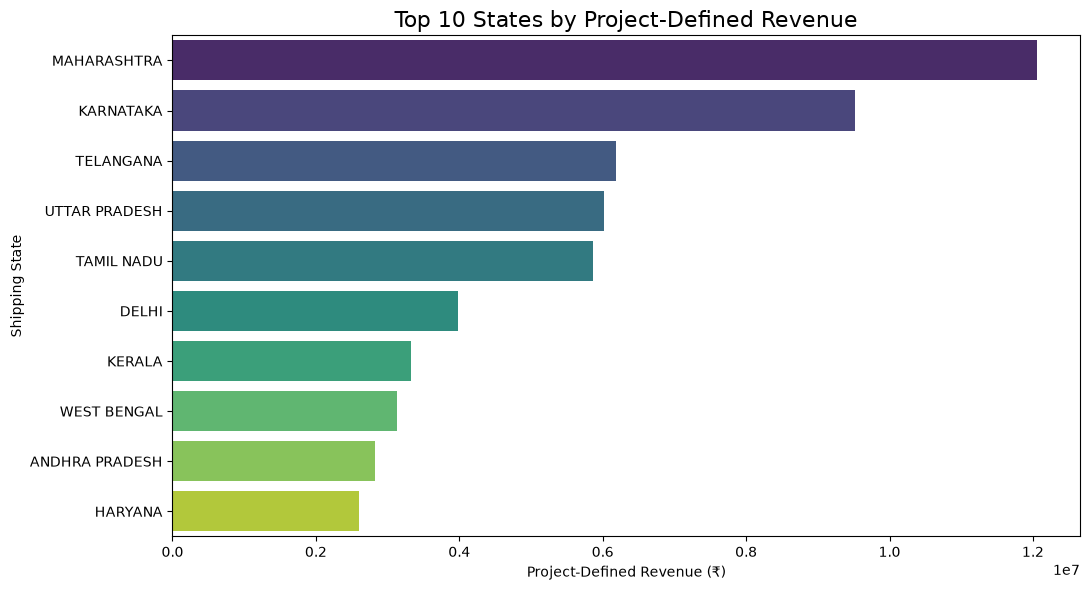

In [74]:
top_10_states = (
    state_sales_summary
    .head(10)
    .reset_index()
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_10_states,
    x="project_defined_revenue",
    y="ship_state",
    hue="ship_state",
    palette="viridis",
    legend=False
)

plt.title("Top 10 States by Project-Defined Revenue", fontsize=16)
plt.xlabel("Project-Defined Revenue (₹)")
plt.ylabel("Shipping State")
plt.tight_layout()
plt.show()

### 19. Analyze Revenue Concentration by State

This section measures the contribution of each shipping state to the total project-defined revenue in the dataset.

For each state, the analysis calculates project-defined revenue and its percentage of the overall project-defined revenue. States will be ranked by revenue contribution to identify the largest contributors.

Records classified under Unknown shipping state will remain included so that the analysis accounts for the full dataset.


In [76]:
state_revenue_concentration = (
    df.groupby("ship_state")
    .agg(
        project_defined_revenue=("revenue", "sum")
    )
    .sort_values("project_defined_revenue", ascending=False)
)

total_project_defined_revenue = df["revenue"].sum()

state_revenue_concentration["revenue_percentage"] = (
    state_revenue_concentration["project_defined_revenue"]
    / total_project_defined_revenue
    * 100
)

state_revenue_concentration.head(15).round(2)

,project_defined_revenue,revenue_percentage
ship_state,,
MAHARASHTRA,12053998.0,17.15
KARNATAKA,9522813.0,13.55
TELANGANA,6184512.0,8.80
UTTAR PRADESH,6023110.0,8.57
TAMIL NADU,5860646.0,8.34
DELHI,3981565.0,5.67
KERALA,3327231.0,4.73
WEST BENGAL,3125170.0,4.45
ANDHRA PRADESH,2823852.0,4.02


### 19.1 Visualize Revenue Concentration by State

A horizontal bar chart compares the percentage contribution of the top 15 shipping states to total project-defined revenue.

This visualization highlights the largest geographical contributors and shows how their shares compare. Percentages are calculated using project-defined revenue across the entire dataset, including records classified under Unknown shipping state.


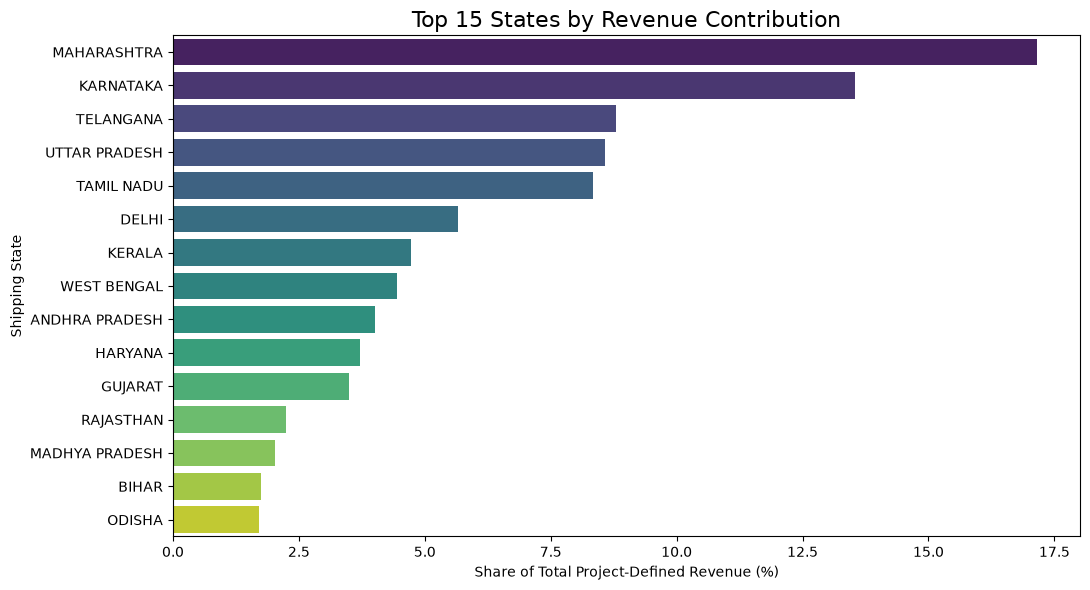

In [77]:
top_15_state_contributions = (
    state_revenue_concentration
    .head(15)
    .reset_index()
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_15_state_contributions,
    x="revenue_percentage",
    y="ship_state",
    hue="ship_state",
    palette="viridis",
    legend=False
)

plt.title("Top 15 States by Revenue Contribution", fontsize=16)
plt.xlabel("Share of Total Project-Defined Revenue (%)")
plt.ylabel("Shipping State")
plt.tight_layout()
plt.show()

## 20. Summary of Exploratory Data Analysis

The exploratory data analysis examined order activity, monetary values, product characteristics, fulfilment information, and geographical patterns in the RetailPulse dataset.

### Overall Sales Performance

* The dataset contains 128,969 records and 120,378 distinct order IDs.
* Total recorded amount is ₹78.59 million.
* Project-defined revenue is ₹70.28 million, calculated using the business rule established during feature engineering.

### Order Status Analysis

* In Progress is the largest consolidated status group, representing 61.84% of records.
* Delivered accounts for 22.31% of records.
* Cancelled records represent 14.21% of records.
* Recorded amounts for cancelled, returned, rejected, and other records do not contribute to project-defined revenue under the chosen business rule.

### Time-Based Analysis

* April has the highest recorded amount and project-defined revenue among the four months represented.
* Recorded amount, project-defined revenue, record count, and distinct order count decline from April through June.
* Sunday has the highest recorded monetary values among the weekdays, while Thursday has the lowest.

### Product Analysis

* Standard sizes account for 86.89% of records.
* Standard sizes also have the highest total recorded amount and project-defined revenue.
* JNE3797 is the highest-ranked product style by total recorded amount among the styles examined.

### Fulfilment Analysis

* Easy Ship is explicitly identified for 30.45% of records.
* The remaining 69.55% are classified as Unknown because fulfilment information was missing.
* The Unknown category has higher monetary totals, but this reflects records with missing fulfilment information rather than a confirmed fulfilment method.

### Geographical Analysis

* Maharashtra is the leading state by project-defined revenue, contributing 17.15% of the total.
* Karnataka ranks second, contributing 13.55%.
* The top five states collectively account for 56.41% of project-defined revenue.

### Data Interpretation Considerations

* Record counts and distinct order counts are different measures because an order may contain multiple records.
* Project-defined revenue is an analytical measure based on the project's chosen business rule, not verified accounting revenue.
* Missing fulfilment and courier status information was handled during data cleaning and should be considered when interpreting results.
* The dataset contains monthly records from March through June; conclusions should be limited to the period represented in the data.
